<a href="https://colab.research.google.com/github/haricharansai/Deep-Learning-With-Accelerated-Computing-2.2/blob/main/Skill-8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install psutil -q


In [2]:
import torch
import psutil
import time
import numpy as np
import platform
import matplotlib.pyplot as plt

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CPU:", platform.processor())
print("RAM:", round(psutil.virtual_memory().total / (1024**3), 2), "GB")
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

Python: 3.13.16
PyTorch: 2.14.1+cu130
CPU: x86_64
RAM: 12.67 GB
GPU Available: True
GPU Name: Tesla T4


In [3]:
cpu_usage = psutil.cpu_percent(interval=1)
ram_usage = psutil.virtual_memory().percent

print("CPU Usage:", cpu_usage, "%")
print("RAM Usage:", ram_usage, "%")
print("Available RAM:",
      round(psutil.virtual_memory().available / (1024**3), 2), "GB")

CPU Usage: 55.3 %
RAM Usage: 11.5 %
Available RAM: 11.22 GB


In [4]:
size = 2000

A = np.random.rand(size, size)
B = np.random.rand(size, size)

start = time.time()

C = np.dot(A, B)

cpu_time = time.time() - start

print("CPU Matrix Multiplication")
print("Matrix Size:", size, "x", size)
print("Execution Time:", round(cpu_time, 4), "seconds")

CPU Matrix Multiplication
Matrix Size: 2000 x 2000
Execution Time: 0.5984 seconds


In [5]:
if torch.cuda.is_available():

    size = 2000

    A = torch.rand(size, size, device="cuda")
    B = torch.rand(size, size, device="cuda")

    # Warm-up
    for _ in range(3):
        torch.matmul(A, B)

    torch.cuda.synchronize()

    start = time.time()

    C = torch.matmul(A, B)

    torch.cuda.synchronize()

    gpu_time = time.time() - start

    print("GPU Matrix Multiplication")
    print("Execution Time:", round(gpu_time, 4), "seconds")

else:
    print("GPU not available. Enable GPU in Colab settings.")

GPU Matrix Multiplication
Execution Time: 0.0075 seconds


In [6]:
if torch.cuda.is_available():

    data = torch.rand(10_000_000)

    start = time.time()

    gpu_data = data.to("cuda")

    torch.cuda.synchronize()

    transfer_time = time.time() - start

    print("Data Transfer Size:",
          round(data.nelement() * data.element_size() / (1024**2), 2),
          "MB")

    print("CPU to GPU Transfer Time:",
          round(transfer_time, 5), "seconds")

else:
    print("GPU unavailable")

Data Transfer Size: 38.15 MB
CPU to GPU Transfer Time: 0.03272 seconds


In [7]:
if torch.cuda.is_available():

    allocated = torch.cuda.memory_allocated(0) / (1024**2)
    reserved = torch.cuda.memory_reserved(0) / (1024**2)
    total = torch.cuda.get_device_properties(0).total_memory / (1024**2)

    print("GPU Memory Allocated:", round(allocated, 2), "MB")
    print("GPU Memory Reserved:", round(reserved, 2), "MB")
    print("Total GPU Memory:", round(total, 2), "MB")

else:
    print("GPU unavailable")

GPU Memory Allocated: 94.27 MB
GPU Memory Reserved: 108.0 MB
Total GPU Memory: 14912.69 MB


In [8]:
if torch.cuda.is_available():

    print("CPU Time:", round(cpu_time, 4), "seconds")
    print("GPU Time:", round(gpu_time, 4), "seconds")

    speedup = cpu_time / gpu_time

    print("GPU Speedup:", round(speedup, 2), "x")

else:
    print("GPU benchmark unavailable")

CPU Time: 0.5984 seconds
GPU Time: 0.0075 seconds
GPU Speedup: 79.49 x


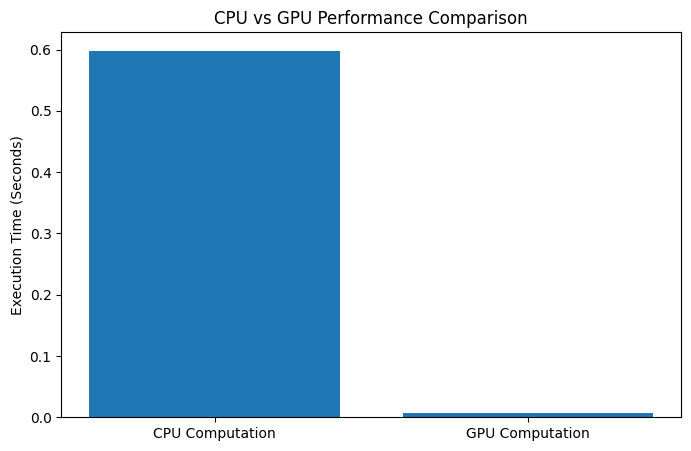

In [9]:
labels = ["CPU Computation", "GPU Computation"]
times = [cpu_time, gpu_time] if torch.cuda.is_available() else [cpu_time, 0]

plt.figure(figsize=(8, 5))
plt.bar(labels, times)

plt.ylabel("Execution Time (Seconds)")
plt.title("CPU vs GPU Performance Comparison")
plt.show()

In [10]:
print("SYSTEM BOTTLENECK ANALYSIS")

print("--------------------------------")

if cpu_usage > 80:
    print("Possible CPU Bottleneck")

if ram_usage > 85:
    print("Possible RAM Bottleneck")

if torch.cuda.is_available():

    if gpu_time > cpu_time:
        print("GPU is slower for this particular workload")

    else:
        print("GPU performs faster for this workload")

    print("GPU Memory Allocated:",
          round(torch.cuda.memory_allocated() / (1024**2), 2), "MB")

else:
    print("GPU unavailable: GPU bottleneck analysis skipped")

print("--------------------------------")
print("Analysis completed")

SYSTEM BOTTLENECK ANALYSIS
--------------------------------
GPU performs faster for this workload
GPU Memory Allocated: 94.27 MB
--------------------------------
Analysis completed
